# NSDUH 2021–2024 — Data Cleaning Pipeline
**CSE 3104 Final Project** · Caitlin Bui, Chloe Doan, Erica Kang

This notebook turns the raw concatenated NSDUH public-use file (**232,441 respondents × 2,638 variables**) into a small, analysis-ready table that answers the proposal's questions:

| Proposal question | What the cleaned data provides |
|---|---|
| Did depression rise, fall, or level off 2021→2024? | `mde_py` / `mde_lt` (past-year / lifetime major depressive episode) for every year |
| Do changes differ by age, sex, race/ethnicity, college enrollment? | `age_group`, `sex`, `race_eth`, `race_eth5`, `college_status`, `college_ft_vs_other` |
| Psychological distress (adults) | `k6_pm`, `k6_py_max`, `spd_pm`, `spd_py` (Kessler K6, ages 18+) |
| Mental health treatment received | `mh_tx_py`, `mde_tx` |
| Valid national estimates | survey weights `wt_1yr`…`wt_4yr`, strata `strata`, replicate/PSU `psu` |

**Pipeline stages**

1. Read **metadata only** (names + labels) — no need to load 2,638 columns
2. **Select** ~25 variables, resolving name differences automatically
3. **Load** only those columns
4. **Inspect** the codes each variable uses
5. **Recode missing-value codes** using SAMHSA's own Stata syntax file
6. **Derive** analysis variables (age group, race/ethnicity, college status, unified MDE…)
7. **Validate** with automated checks
8. **Save** a Parquet file + data dictionary

Each step has a short *what / why* note so the reasoning can go straight into the report.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import pyreadstat

DATA_DIR = Path("Data")
DTA_PATH = DATA_DIR / "NSDUH_2021_2024.dta"
DO_PATH  = DATA_DIR / "NSDUH_2021_2024-data-stata-supplemental-syntax.do"
OUT_DIR  = DATA_DIR / "clean"
OUT_DIR.mkdir(parents=True, exist_ok=True)

STUDY_YEARS = [2021, 2022, 2023, 2024]

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", None)
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Read metadata only

**What:** read just the column names, variable labels, and value labels.

**Why:** the full file is 232,441 × 2,638 ≈ 613 million cells (~4.9 GB as float64). We only need ~25 columns, so loading everything wastes memory and time. `metadataonly=True` returns in seconds and also gives us the **value labels** stored in the `.dta`, which we use throughout to confirm what each code means instead of guessing.

**Column-name case:** the file mixes cases (`year`, `verep`, `irmarit` vs `AGE3`, `NEWRACE2`). SAMHSA's `.do` file starts with `rename *, upper`, so we mirror that and refer to every variable in UPPERCASE.

In [2]:
_, meta = pyreadstat.read_dta(str(DTA_PATH), metadataonly=True)

UPPER_TO_ORIG = {c.upper(): c for c in meta.column_names}
VAR_LABELS    = {c.upper(): lbl for c, lbl in meta.column_names_to_labels.items()}
VALUE_LABELS  = {c.upper(): lbls for c, lbls in meta.variable_value_labels.items()}

print(f"{meta.number_rows:,} rows x {len(meta.column_names):,} columns")

PyreadstatError: File Data/NSDUH_2021_2024.dta does not exist!

In [ ]:
def search_vars(pattern):
    # Find variables whose NAME or LABEL matches a regex — handy for checking codebook names.
    rx = re.compile(pattern, re.I)
    hits = [(v, VAR_LABELS.get(v, "")) for v in UPPER_TO_ORIG
            if rx.search(v) or rx.search(VAR_LABELS.get(v, "") or "")]
    return pd.DataFrame(hits, columns=["variable", "label"])

def value_labels(var):
    return VALUE_LABELS.get(var.upper(), {})

# Example: everything related to depression / distress / college
search_vars(r"MDE|K6|SPD|COLLENR")

## 2. Select variables

**What:** map each *concept* in the proposal to one or more candidate NSDUH variable names, and keep the first name that exists in the file.

**Why:** NSDUH occasionally renames variables between releases (e.g. strata `VESTR` → `VESTR_C` in concatenated files). Listing candidates makes the pipeline robust and tells us immediately if a required variable is missing, rather than failing later.

| Concept | NSDUH variable | Universe | Notes |
|---|---|---|---|
| Respondent ID | `QUESTID2` | all | if absent, we create one |
| Survey year | `YEAR` | all | |
| Age category | `AGE3` | all | 1–3 = 12–17, 4–6 = 18–25 |
| Sex | `IRSEX` | all | imputed, no missing |
| Race/ethnicity | `NEWRACE2` | all | 7 categories |
| College enrollment | `COLLENRLST` | **ages 18–22 only** | SAMHSA's own recode; uses exact age internally |
| Youth MDE (lifetime / past year) | `YMDELT`, `YMDEYR` | 12–17 | adolescent module |
| Adult MDE (lifetime / past year) | `AMDELT`, `AMDEYR` | 18+ | adult module |
| K6 distress score | `K6SCMON`, `K6SCMAX` | 18+ | 0–24 |
| Serious psychological distress | `SPDMON`, `SPDYR` | 18+ | K6 ≥ 13 |
| Mental health treatment | `MHTRTPY` (or older `AMHTXRC*`) | varies | treatment questions were redesigned in 2021+ |
| Treatment for depression (if MDE) | `YMDETXRX`, `AMDETXRX` | MDE cases | |
| Design | `VESTR_C`, `VEREP`, `ANALWT2_C1–C4` | all | needed for correct estimates |

`REQUIRED` concepts stop the pipeline if missing; the others are optional and are simply reported. If something optional isn't found, use `search_vars("...")` above to find its current name and add it to the candidate list.

In [ ]:
VARIABLE_CANDIDATES = {
    # concept          candidate names (first match wins)
    "resp_id":        ["QUESTID2", "QUESTID"],
    "year":           ["YEAR"],
    "age_cat":        ["AGE3"],
    "sex":            ["IRSEX"],
    "race_eth":       ["NEWRACE2"],
    "college_enroll": ["COLLENRLST"],
    # school variables are only a fallback if COLLENRLST is absent
    "school_now":     ["EDUSCHLGO"],
    "school_grade":   ["EDUSCHGRD2"],
    "school_ftpt":    ["EDUFULPAR"],
    # depression
    "ymde_lt":        ["YMDELT"],
    "ymde_py":        ["YMDEYR"],
    "amde_lt":        ["AMDELT"],
    "amde_py":        ["AMDEYR"],
    # psychological distress (adults)
    "k6_pm":          ["K6SCMON"],
    "k6_py_max":      ["K6SCMAX"],
    "spd_pm":         ["SPDMON", "SPDPSTMON"],
    "spd_py":         ["SPDYR", "SPDPSTYR"],
    # treatment
    "mh_tx_py":       ["MHTRTPY", "AMHTXRC4", "AMHTXRC3"],
    "ymde_tx":        ["YMDETXRX"],
    "amde_tx":        ["AMDETXRX"],
    # survey design
    "strata":         ["VESTR_C", "VESTR"],
    "psu":            ["VEREP"],
    "wt_1yr":         ["ANALWT2_C1", "ANALWT_C"],
    "wt_2yr":         ["ANALWT2_C2"],
    "wt_3yr":         ["ANALWT2_C3"],
    "wt_4yr":         ["ANALWT2_C4"],
}
REQUIRED = {"year", "age_cat", "sex", "race_eth",
            "ymde_py", "amde_py", "strata", "psu", "wt_1yr"}

SRC = {}          # concept -> NSDUH variable actually used
not_found = []
for concept, cands in VARIABLE_CANDIDATES.items():
    hit = next((c for c in cands if c in UPPER_TO_ORIG), None)
    (SRC.__setitem__(concept, hit) if hit else not_found.append(concept))

missing_required = REQUIRED & set(not_found)
if missing_required:
    raise KeyError(f"Required variables not found: {missing_required}. "
                   "Use search_vars() to locate their names in this release.")

print("Not found (optional):", not_found or "none")
pd.DataFrame([(k, v, VAR_LABELS.get(v, "")) for k, v in SRC.items()],
             columns=["concept", "nsduh_var", "label"])

## 3. Load only the selected columns

**What:** re-read the `.dta` with `usecols=` so only ~25 columns are loaded.

**Why:** this is the "trim the large file" step from the proposal's roadblocks. It cuts memory from gigabytes to a few dozen MB and makes every later step fast.

We also keep an untouched copy (`raw`) before any recoding. Some skip codes carry real information — e.g. a *legitimate skip* on a school-grade question means "not in school" — so derived variables that need those codes are built from `raw`.

In [ ]:
usecols = [UPPER_TO_ORIG[v] for v in SRC.values()]
df, _ = pyreadstat.read_dta(str(DTA_PATH), usecols=usecols)
df.columns = df.columns.str.upper()

if "resp_id" not in SRC:                      # build a stable ID if none exists
    df.insert(0, "RESP_ID", np.arange(1, len(df) + 1))
    SRC["resp_id"] = "RESP_ID"

raw = df.copy()
print(df.shape, f"— {df.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory")
df.head()

## 4. Inspect each variable's codes

**What:** print the label, value labels, and observed values for every kept variable.

**Why:** before recoding anything, we confirm what each code means *in this file*. This catches surprises like recode variables using `1 = Yes / 2 = No` while others use `1 = Yes / 0 = No`, and shows which special codes (85, 94, 97, 98, 99, -9) actually appear.

In [ ]:
DESIGN_VARS = {SRC[k] for k in ("strata", "psu", "wt_1yr", "wt_2yr", "wt_3yr", "wt_4yr") if k in SRC}

for concept, var in SRC.items():
    if var in DESIGN_VARS or var == SRC["resp_id"]:
        continue
    vc = raw[var].value_counts(dropna=False).sort_index()
    print(f"\n=== {var}  ({concept}) — {VAR_LABELS.get(var, '')}")
    if value_labels(var):
        print("value labels:", value_labels(var))
    print(vc.head(30).to_string() if len(vc) <= 30 else
          f"{len(vc)} distinct values; min={raw[var].min()}, max={raw[var].max()}")

## 5. Recode missing-value codes

**What:** replace NSDUH's numeric "special" codes with real missing values (`NaN`).

NSDUH uses numbers for non-answers (from the codebook):

| Code | Meaning | Treat as missing? |
|---|---|---|
| 85 | Bad data (logically assigned) | yes |
| 94 | Don't know | yes |
| 97 | Refused | yes |
| 98 | Blank / no answer | yes |
| 99 | Legitimate skip (question not asked) | usually — but it can carry meaning |
| 81, 91 | Never used (substance items) | **no** — a real answer |
| 83, 93 | Did not use in period (substance items) | **no** — a real answer |
| -9 | Variable **not collected in that year** (concatenated file only) | yes |

**Why not just replace 85–99 everywhere?** Because the cutoff differs by variable. Continuous items (ages, day counts) use 985/9985 codes, some items start at 94, and on others 91/93 are valid answers. Replacing blindly would delete real data or leave codes like 994 in place and wreck averages.

**How:** SAMHSA ships the exact per-variable cutoff in the Stata syntax file (`replace X = . if (X >= cutoff)`). We **parse that file** into a rule dictionary, so our recoding is identical to SAMHSA's and stays correct when we add variables.

⚠️ **Bug in the `.do` file:** about 600 lines read `replace X = . if (X >= -9)`. Taken literally, that sets *every* value to missing (all valid codes are ≥ -9). The intent is clearly "-9 means not collected this year", so we treat those as `X == -9`.

Recoded/imputed variables (e.g. `AMDEYR`, `IRSEX`, `NEWRACE2`, K6 scores) have no user-defined missing codes and aren't in the `.do` file; for them we only convert negative codes (-9). Design variables are never touched.

In [ ]:
def parse_do_missing_rules(do_path):
    # Return {VARIABLE: cutoff} from lines like:  replace X = . if (X >= 85 )
    text = Path(do_path).read_text(errors="ignore")
    pat = re.compile(r"replace\s+(\w+)\s*=\s*\.\s*if\s*\(\s*\1\s*>=\s*(-?\d+)\s*\)", re.I)
    return {m.group(1).upper(): int(m.group(2)) for m in pat.finditer(text)}

MISSING_RULES = parse_do_missing_rules(DO_PATH)
n_neg9 = sum(v == -9 for v in MISSING_RULES.values())
print(f"Parsed {len(MISSING_RULES):,} rules from the .do file ({n_neg9} use the '>= -9' form)")

In [ ]:
def recode_missing(frame, rules, skip=()):
    # Apply SAMHSA missing-value rules; return (clean frame, log table).
    out, log = frame.copy(), []
    for col in out.columns:
        if col in skip:
            continue

        # Some columns can load as text; convert them if they're really numbers
        if not pd.api.types.is_numeric_dtype(out[col]):
            converted = pd.to_numeric(out[col], errors="coerce")
            newly_nan = converted.isna() & out[col].notna()
            if newly_nan.mean() > 0.01:   # mostly non-numeric -> genuine text column
                log.append({"variable": col, "rule": "SKIPPED (text column)",
                            "n_recoded": 0,
                            "pct_missing_after": round(100 * out[col].isna().mean(), 2)})
                continue
            out[col] = converted

        cutoff = rules.get(col)
        s = out[col]
        if cutoff is None or cutoff < 0:
            mask, rule = s < 0, "negative codes (-9) only"
        else:
            mask, rule = (s >= cutoff) | (s < 0), f">= {cutoff}  (+ -9)"
        log.append({"variable": col, "rule": rule,
                    "n_recoded": int(mask.sum()),
                    "pct_missing_after": round(100 * (s.isna() | mask).mean(), 2)})
        out.loc[mask, col] = np.nan
    return out, pd.DataFrame(log)

df, missing_log = recode_missing(df, MISSING_RULES, skip=DESIGN_VARS | {SRC["resp_id"]})
missing_log

**Missingness by year.** A variable that is ~100% missing in one year wasn't asked that year — important because the whole project compares years. Expect high missingness for youth items among adults (and vice versa); that's by design, not a data problem.

In [ ]:
check_vars = [v for k, v in SRC.items() if v not in DESIGN_VARS | {SRC["resp_id"], SRC["year"]}]
(df[check_vars].isna().groupby(df[SRC["year"]]).mean() * 100).round(1).T

## 6. Derive analysis variables

### 6a. Age group, sex, race/ethnicity

**Age group** comes from `AGE3` (1–3 = 12–17, 4–6 = 18–25, 7+ = 26+). We keep 26+ in the file (see Step 7 for why) but label it.

**Race/ethnicity:** `race_eth` keeps all 7 NSDUH categories. `race_eth5` collapses the three smallest groups (American Indian/Alaska Native, Native Hawaiian/Pacific Islander, multiracial) into *Other / Multiracial*. **Why:** the proposal flags that 18–22 college students broken down by race may have too few respondents per year; the collapsed version gives more stable yearly estimates, while the 7-group version is still available for pooled (multi-year) analysis.

All labelled variables are ordered categoricals so tables and plots sort sensibly.

In [ ]:
def ordered_cat(series, mapping):
    return pd.Categorical(series.map(mapping), categories=list(dict.fromkeys(mapping.values())), ordered=True)

AGE_GROUP = {1: "12-17", 2: "12-17", 3: "12-17",
             4: "18-25", 5: "18-25", 6: "18-25",
             7: "26+", 8: "26+", 9: "26+", 10: "26+", 11: "26+"}
SEX = {1: "Male", 2: "Female"}
RACE7 = {1: "White", 2: "Black", 3: "AIAN", 4: "NHPI", 5: "Asian",
         6: "Multiracial", 7: "Hispanic"}
RACE5 = {1: "White", 2: "Black", 7: "Hispanic", 5: "Asian",
         3: "Other/Multiracial", 4: "Other/Multiracial", 6: "Other/Multiracial"}

print("AGE3 labels:", value_labels(SRC["age_cat"]))
print("IRSEX labels:", value_labels(SRC["sex"]))
print("NEWRACE2 labels:", value_labels(SRC["race_eth"]))

clean = pd.DataFrame({
    "resp_id":   df[SRC["resp_id"]],
    "year":      df[SRC["year"]].astype("int16"),
    "age_cat":   df[SRC["age_cat"]].astype("Int8"),
    "age_group": ordered_cat(df[SRC["age_cat"]], AGE_GROUP),
    "sex":       ordered_cat(df[SRC["sex"]], SEX),
    "race_eth":  ordered_cat(df[SRC["race_eth"]], RACE7),
    "race_eth5": ordered_cat(df[SRC["race_eth"]], RACE5),
})
clean[["age_group", "sex", "race_eth5"]].apply(lambda s: s.value_counts(dropna=False)).T

### 6b. College enrollment (ages 18–22)

**What:** `college_status` = Full-time college / Part-time college / Not enrolled, and `college_ft_vs_other` = Full-time student vs everyone else aged 18–22.

**Why `COLLENRLST`:** the public file only gives age in bands (`AGE3` 4 = 18–20, 5 = 21–23), so we *cannot* isolate exactly 18–22 ourselves. SAMHSA's `COLLENRLST` recode is built from exact age and is only defined for 18–22, so it's the correct source.

**How the codes are mapped (no guessing):**
- A code is "age-ineligible" if it appears among 12–17-year-olds or adults 26+ — those people can't be 18–22. Done from the data, not from label text.
- Among eligible codes, the value label decides Full-time vs Part-time; everything else is "Not enrolled".
- The mapping table is printed for you to confirm, and an assertion checks that everyone placed in the 18–22 group is in `AGE3` 4 or 5.

**Comparison group:** the proposal compares full-time students to non-students. SAMHSA's college reports compare *full-time students* to *all other 18–22-year-olds* (part-time + not enrolled). We provide both so you can choose; just state which one you used.

In [ ]:
def _num(s):
    return pd.to_numeric(s, errors="coerce")

def codes_where(var, pattern):
    # Codes of `var` whose value label matches the regex
    return [k for k, v in value_labels(var).items() if re.search(pattern, str(v), re.I)]

# ---- Make sure the enrollment recodes are loaded (no need to rerun Steps 2-3) ----
for concept, cands in {"college_enroll": ["ENRLCOLLST2", "COLLENRLST"],
                       "college_ft":     ["ENRLCOLLFT2"]}.items():
    hit = next((c for c in cands if c in UPPER_TO_ORIG), None)
    if hit is None:
        continue
    SRC[concept] = hit
    if hit not in raw.columns:
        extra, _ = pyreadstat.read_dta(str(DTA_PATH), usecols=[UPPER_TO_ORIG[hit]])
        extra.columns = extra.columns.str.upper()
        assert len(extra) == len(raw), "row count mismatch when loading extra column"
        raw[hit] = extra[hit].values
print("college_enroll ->", SRC.get("college_enroll"), "| college_ft ->", SRC.get("college_ft"))


def build_college_status(raw, age_cat):
    var = SRC.get("college_enroll")
    age_cat = _num(age_cat)

    # ---- Option A: SAMHSA enrollment recode (exact ages 18-22) ----
    if var is not None:
        codes = _num(raw[var])
        labels = value_labels(var)
        print(f"Using {var}: {labels}\n")
        rows = []
        for code_ in sorted(codes.dropna().unique()):
            ages = age_cat[codes == code_]
            lbl = labels.get(code_, "")
            if ages.isin([1, 2, 3]).any() or (ages >= 7).any():
                status = None                      # code used by people who can't be 18-22
            elif re.search(r"full", lbl, re.I):
                status = "Full-time college"
            elif re.search(r"part", lbl, re.I):
                status = "Part-time college"
            else:
                status = "Not enrolled"
            rows.append({"code": code_, "label": lbl, "n": int((codes == code_).sum()),
                         "AGE3 range": f"{ages.min()}–{ages.max()}", "assigned": status})
        mapping = pd.DataFrame(rows)
        status = codes.map(dict(zip(mapping["code"], mapping["assigned"])))
        return status, mapping

    # ---- Option B: derive from raw school questions (ages 18-23 via AGE3) ----
    print("No enrollment recode found — deriving from raw school questions (ages 18–23).\n")
    need = {"school_now", "school_grade", "school_ftpt"} - set(SRC)
    if need:
        raise KeyError(f"No enrollment recode and missing school variables: {need}")
    go, grd, ft = (_num(raw[SRC[k]]) for k in ("school_now", "school_grade", "school_ftpt"))
    v_go, v_grd, v_ft = SRC["school_now"], SRC["school_grade"], SRC["school_ftpt"]
    for v in (v_go, v_grd, v_ft):
        print(f"{v}: {value_labels(v)}")

    yes_codes     = codes_where(v_go,  r"\byes\b")          # 1 = Yes, 11 = Yes (logically assigned)
    college_codes = codes_where(v_grd, r"college|universit|graduate")
    full_codes    = codes_where(v_ft,  r"full")
    part_codes    = codes_where(v_ft,  r"part")
    unknown_codes = [85, 94, 97, 98]
    print("\nattending =", yes_codes, "| college grades =", college_codes,
          "| full-time =", full_codes, "| part-time =", part_codes)
    assert yes_codes and college_codes and full_codes, "label match failed — set the code lists by hand"

    in_scope   = age_cat.isin([4, 5])
    in_college = go.isin(yes_codes) & grd.isin(college_codes)
    unknown    = go.isin(unknown_codes) | (go.isin(yes_codes) & grd.isin(unknown_codes))
    status = pd.Series(np.select(
        [~in_scope, unknown,
         in_college & ft.isin(full_codes),
         in_college & ft.isin(part_codes),
         in_college],
        [None, None, "Full-time college", "Part-time college", None],
        default="Not enrolled"), index=raw.index, dtype=object)

    print(f"\nShare of 18-23 with a real answer to {v_go}: {(~go[in_scope].isin([99])).mean():.1%}")
    mapping = status[in_scope].value_counts(dropna=False).rename_axis("assigned").reset_index(name="n")
    return status, mapping


college_status, college_map = build_college_status(raw, raw[SRC["age_cat"]])
display(college_map)

clean["college_status"] = pd.Categorical(
    college_status, categories=["Full-time college", "Part-time college", "Not enrolled"], ordered=True)
clean["college_ft_vs_other"] = pd.Categorical(
    np.where(clean["college_status"].isna(), None,
             np.where(clean["college_status"] == "Full-time college", "Full-time student", "Other 18-22")),
    categories=["Full-time student", "Other 18-22"])
clean["age_18_22"] = clean["college_status"].notna()

# Validation
assert clean["age_18_22"].any(), "no one assigned a college status — check the mapping table"
assert clean.loc[clean["age_18_22"], "age_cat"].isin([4, 5]).all(), "college status assigned outside ages 18–23"
assert (clean["college_status"] == "Full-time college").any(), "no full-time students found — check labels"

# Cross-check against SAMHSA's full-time flag (should line up one-to-one)
if "college_ft" in SRC:
    print(f"\n{SRC['college_ft']} labels:", value_labels(SRC["college_ft"]))
    display(pd.crosstab(clean["college_status"], _num(raw[SRC["college_ft"]]).rename(SRC["college_ft"]),
                        dropna=False))

pd.crosstab(clean["year"], clean["college_status"], margins=True)

### 6c. Depression, distress, and treatment → clean 0/1 indicators

**What:** convert outcome variables to `1 = yes, 0 = no, NaN = missing/not applicable`.

**Why:** NSDUH recodes use `1 = Yes, 2 = No`. With 0/1, a (weighted) mean *is* the prevalence, which makes every later table one line of code. The helper checks the observed values first and refuses to guess if the coding is unexpected.

**Unified MDE:** `mde_py` / `mde_lt` take the **youth** measure for 12–17 and the **adult** measure for 18+, so one column tracks depression across both groups. We also keep the separate youth/adult columns.

⚠️ **For the report:** youth and adult MDE come from different questionnaire modules (wording adapted for adolescents), and SAMHSA advises caution comparing them directly. Comparing *trends* within each group (e.g. "did 12–17 rise more than 18–25?") is fine; comparing levels across groups should come with that caveat.

**K6 / SPD** are only asked of adults, so they stay missing for 12–17 by design — they can't be used for the adolescent comparison.

In [ ]:
def to_binary(s, name):
    vals = set(s.dropna().unique())
    if vals <= {0, 1}:
        return s.astype("Int8")
    if vals <= {1, 2}:
        return s.map({1: 1, 2: 0}).astype("Int8")
    raise ValueError(f"{name}: unexpected values {sorted(vals)[:10]} — check value labels before recoding")

def get(concept):
    return df[SRC[concept]] if concept in SRC else pd.Series(np.nan, index=df.index)

is_youth = clean["age_group"] == "12-17"
is_adult = clean["age_group"].isin(["18-25", "26+"])

for c in ["ymde_lt", "ymde_py", "amde_lt", "amde_py", "spd_pm", "spd_py", "mh_tx_py", "ymde_tx", "amde_tx"]:
    if c in SRC:
        clean[c] = to_binary(get(c), SRC[c])

# Unified depression measures (youth module for 12–17, adult module for 18+)
def col(c):
    return clean[c] if c in clean else pd.Series(pd.NA, index=clean.index, dtype="Int8")

clean["mde_py"] = col("ymde_py").where(is_youth, col("amde_py")).where(is_youth | is_adult)
clean["mde_lt"] = col("ymde_lt").where(is_youth, col("amde_lt")).where(is_youth | is_adult)
if "ymde_tx" in clean or "amde_tx" in clean:
    clean["mde_tx"] = col("ymde_tx").where(is_youth, col("amde_tx"))

# K6 scores stay numeric (0–24); adults only
for c in ["k6_pm", "k6_py_max"]:
    if c in SRC:
        clean[c] = get(c).where(is_adult)

# Sanity: youth MDE should only exist for youths, adult MDE only for adults
pd.DataFrame({
    "ymde_py non-missing": clean.groupby("age_group", observed=True)["ymde_py"].count(),
    "amde_py non-missing": clean.groupby("age_group", observed=True)["amde_py"].count(),
})

### 6d. Survey design variables

**What:** keep strata (`VESTR_C`), replicate/PSU (`VEREP`), and all four weight versions.

**Why:** NSDUH oversamples some groups, so unweighted percentages are **not** national estimates. The concatenated file provides weights pre-divided for pooling:

| Weight | Use when… |
|---|---|
| `wt_1yr` (`ANALWT2_C1`) | estimating **one year at a time** — the main year-by-year trend |
| `wt_2yr` / `wt_3yr` | pooling 2 or 3 years |
| `wt_4yr` (`ANALWT2_C4`) | pooling **all four years**, e.g. small groups like Asian full-time students |

Strata + PSU are needed for correct standard errors / confidence intervals (Taylor linearization), e.g. with Python's `samplics` or R's `survey` package. Point estimates only need the weight.

In [ ]:
for k in ["strata", "psu", "wt_1yr", "wt_2yr", "wt_3yr", "wt_4yr"]:
    if k in SRC:
        clean[k] = df[SRC[k]]

# The pooled weights should be exact fractions of the single-year weight
for k, d in [("wt_2yr", 2), ("wt_3yr", 3), ("wt_4yr", 4)]:
    if k in clean:
        assert np.allclose(clean[k], clean["wt_1yr"] / d, rtol=1e-6), f"{k} is not wt_1yr/{d}"
assert (clean["wt_1yr"] > 0).all(), "non-positive weights found"
print("weight checks passed")

## 7. Define the study population (flag, don't drop)

**What:** add `in_study` = ages 12–25, instead of deleting everyone 26+.

**Why:** in survey analysis, a subgroup should be analysed as a *domain* of the full sample. Dropping rows can remove whole strata/PSUs and make standard errors wrong. The column-trimmed file is small (~30 MB), so keeping all rows costs nothing. For quick EDA we also save a filtered 12–25 copy, but use the full file + `in_study` when computing confidence intervals.

In [ ]:
clean["in_study"] = clean["age_group"].isin(["12-17", "18-25"])
print(clean["in_study"].value_counts())
pd.crosstab(clean["year"], clean["age_group"], margins=True)

## 8. Validate

**What:** automated checks that fail loudly if something upstream is off, plus a quick look at weighted prevalence.

**Why:** a pipeline is only "automated" if it catches its own errors. The checks confirm the four years are present with plausible sizes, every indicator is 0/1/NaN, MDE only exists in the right age group, and K6 is in range.

In [ ]:
binary_cols = [c for c in clean.columns
               if c in {"ymde_lt", "ymde_py", "amde_lt", "amde_py", "mde_lt", "mde_py",
                        "spd_pm", "spd_py", "mh_tx_py", "ymde_tx", "amde_tx", "mde_tx"}]

checks = {
    "all four years present":            set(clean["year"]) == set(STUDY_YEARS),
    "each year has 40k–80k respondents": clean["year"].value_counts().between(40_000, 80_000).all(),
    "resp_id unique within year":        not clean.duplicated(["year", "resp_id"]).any(),
    "no missing age/sex/race":           clean[["age_group", "sex", "race_eth"]].notna().all().all(),
    "indicators are 0/1/NaN":            all(set(clean[c].dropna().unique()) <= {0, 1} for c in binary_cols),
    "youth MDE only for 12-17":          clean.loc[~is_youth, "ymde_py"].isna().all(),
    "adult MDE only for 18+":            clean.loc[is_youth, "amde_py"].isna().all(),
    "K6 within 0–24":                    ("k6_pm" not in clean) or clean["k6_pm"].dropna().between(0, 24).all(),
    "college status only ages 18-23":    clean.loc[clean["age_18_22"], "age_cat"].isin([4, 5]).all(),
}
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
assert all(checks.values()), "Validation failed — see FAIL lines above"

**Weighted prevalence sanity check.** These should be close to SAMHSA's published NSDUH annual detailed tables for past-year MDE by age group — if they are wildly off, a recode is wrong. (Point estimates only; no standard errors here.) The unweighted `n` column flags small cells — SAMHSA suppresses imprecise estimates, and the proposal already anticipates pooling years for small 18–22 subgroups.

In [ ]:
def weighted_prevalence(data, outcome, by, weight="wt_1yr"):
    d = data.dropna(subset=[outcome]).copy()
    d["_wy"] = d[outcome].astype(float) * d[weight]
    g = d.groupby(by, observed=True)
    return pd.DataFrame({"pct": 100 * g["_wy"].sum() / g[weight].sum(),
                         "n_unweighted": g.size()}).round(1)

study = clean[clean["in_study"]]
weighted_prevalence(study, "mde_py", ["year", "age_group"]).unstack("age_group")

In [ ]:
# Same check for the college comparison (ages 18–22)
weighted_prevalence(study[study["age_18_22"]], "mde_py", ["year", "college_ft_vs_other"]).unstack()

## 9. Save outputs

**What:**
- `nsduh_2124_clean.parquet` — all respondents, cleaned (use this with survey-design methods)
- `nsduh_2124_study_12_25.parquet` — ages 12–25 only, for quick EDA / plotting
- `data_dictionary.csv` — every column, its source variable, and its meaning

**Why Parquet:** it preserves data types (ordered categories, nullable integers), is far smaller than CSV, and loads in a fraction of a second, so downstream notebooks don't redo any cleaning. A CSV is also written for anyone without `pyarrow`.

In [ ]:
DESCRIPTIONS = {
    "resp_id": "Respondent ID", "year": "Survey year",
    "age_cat": "AGE3 code (raw)", "age_group": "12-17 / 18-25 / 26+",
    "sex": "Male / Female", "race_eth": "Race/ethnicity, 7 NSDUH groups",
    "race_eth5": "Race/ethnicity, 5 groups (AIAN, NHPI, multiracial combined)",
    "college_status": "Ages 18-22: full-time / part-time / not enrolled",
    "college_ft_vs_other": "Ages 18-22: full-time student vs all other 18-22",
    "age_18_22": "True if respondent is 18-22 (has a college status)",
    "ymde_lt": "Youth lifetime MDE (12-17), 1/0", "ymde_py": "Youth past-year MDE (12-17), 1/0",
    "amde_lt": "Adult lifetime MDE (18+), 1/0", "amde_py": "Adult past-year MDE (18+), 1/0",
    "mde_lt": "Lifetime MDE, youth measure for 12-17 and adult for 18+",
    "mde_py": "Past-year MDE, youth measure for 12-17 and adult for 18+",
    "k6_pm": "K6 distress score past month, 0-24 (18+)",
    "k6_py_max": "K6 distress score, worst month past year, 0-24 (18+)",
    "spd_pm": "Serious psychological distress past month, 1/0 (18+)",
    "spd_py": "Serious psychological distress past year, 1/0 (18+)",
    "mh_tx_py": "Received mental health treatment past year, 1/0",
    "ymde_tx": "Youth with MDE: received treatment for depression, 1/0",
    "amde_tx": "Adult with MDE: received treatment for depression, 1/0",
    "mde_tx": "Received treatment for depression (if MDE), unified",
    "strata": "Variance stratum", "psu": "Variance replicate (PSU)",
    "wt_1yr": "Analysis weight, single-year estimates", "wt_2yr": "Weight for pooling 2 years",
    "wt_3yr": "Weight for pooling 3 years", "wt_4yr": "Weight for pooling all 4 years",
    "in_study": "True if age 12-25 (study population)",
}
dictionary = pd.DataFrame({
    "column": clean.columns,
    "source_variable": [SRC.get(c, "derived") for c in clean.columns],
    "description": [DESCRIPTIONS.get(c, "") for c in clean.columns],
    "dtype": clean.dtypes.astype(str).values,
    "pct_missing": (clean.isna().mean() * 100).round(1).values,
})

clean.to_parquet(OUT_DIR / "nsduh_2124_clean.parquet", index=False)
clean[clean["in_study"]].to_parquet(OUT_DIR / "nsduh_2124_study_12_25.parquet", index=False)
clean.to_csv(OUT_DIR / "nsduh_2124_clean.csv", index=False)
dictionary.to_csv(OUT_DIR / "data_dictionary.csv", index=False)

print(f"Saved {clean.shape[0]:,} rows x {clean.shape[1]} columns to {OUT_DIR}/")
dictionary

## Summary of cleaning decisions (for the report)

1. **Trimmed 2,638 → ~30 columns** by reading metadata first and loading only needed variables.
2. **Missing-value codes recoded with SAMHSA's own per-variable rules**, parsed from the official Stata syntax file; the `>= -9` lines in that file were corrected to `== -9` (not collected that year).
3. **College enrollment** taken from SAMHSA's `COLLENRLST`, since the public file has no exact age to isolate 18–22; codes mapped from the data and checked against age.
4. **Outcomes standardized to 0/1** so weighted means equal prevalences; youth and adult MDE combined into one column but kept separately too, with a caveat about comparing levels across modules.
5. **Race/ethnicity offered at 7 and 5 levels** to manage small cells; `wt_4yr` available for pooled estimates of small groups.
6. **No respondents dropped**; study population flagged with `in_study` so survey standard errors stay valid.
7. **Automated validation checks** stop the pipeline if any assumption breaks.

**Next steps:** compute year-by-group prevalences with confidence intervals using `strata`, `psu`, and `wt_1yr` (e.g. `samplics`), and compare against SAMHSA's published tables before building visualizations.

## 10. EDA 1: Headline trend in past-year MDE, 2021–2024

**What:**

- `fig1_mde_by_age.png`: past-year MDE (%) by year, one line per age group (12–17 and 18–25), with 95% confidence bands
- `fig2_mde_age_by_sex.png`: the same trend split into Male and Female panels, to check whether the decline is shared
- `fig3_slope_2021_2024.png`: a slope chart from 2021 to 2024 for All, Male, and Female in each age group, labelled with the change in percentage points (`*` = statistically significant)

**Key terms:** **MDE** (major depressive episode) means 2+ weeks of depressed mood or loss of interest, plus other symptoms (sleep, appetite, energy, concentration, worthlessness) that affect daily life. It is a survey-based measure, not a clinical diagnosis. **Past-year** means the person reported an episode at some point in the previous 12 months.

**Why design-based estimates:** NSDUH is a complex sample survey, not a simple random sample, so a plain average would be wrong. Each estimate is a weighted proportion using `wt_1yr`, and its standard error is calculated with Taylor linearization using the survey's strata and PSUs. The shaded bands are the resulting 95% confidence intervals, computed with a logit transform so they stay between 0% and 100%. Subgroups are treated as domains of the **full** sample rather than filtered subsets, which is why we kept the 26+ rows.

**How to read it:** Compare trends, not levels. Youth (12–17) and adult (18+) MDE come from different survey modules, so the gap between the lines is not a like-for-like comparison. The `*` on the slope chart means the 2021→2024 change is larger than 1.96 × its standard error, treating the two years as independent samples. Wide bands mean less precise estimates, usually from smaller subgroups.

In [ ]:
# %% [markdown]
# # EDA 1 — Headline trend: past-year MDE, 2021–2024
# Three figures:
#   1. MDE by year, one line per age group (with 95% CI bands)
#   2. Same, faceted by sex
#   3. Slope chart 2021 -> 2024 with the change (in percentage points) labelled
#
# Estimates are design-based: weighted prevalence (wt_1yr) with Taylor-linearized
# standard errors using strata + PSU, computed on the FULL sample with the
# subgroup treated as a domain (this is why we kept the 26+ rows).

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# If you're running this in the cleaning notebook, `clean` already exists.
# Otherwise load it from the parquet the pipeline saved:
try:
    clean
except NameError:
    clean = pd.read_parquet(Path("Data/clean/nsduh_2124_clean.parquet"))

OUTCOME = "mde_py"
WEIGHT  = "wt_1yr"
YEARS   = [2021, 2022, 2023, 2024]
AGE_ORDER = ["12-17", "18-25"]           # study population (add "26+" for context)
COLORS = {"12-17": "#1f77b4", "18-25": "#d62728", "26+": "#7f7f7f",
          "Male": "#2a62c9", "Female": "#e75480", "All": "#333333"}

# Definition shown under every figure
MDE_NOTE = ("MDE = major depressive episode: 2+ weeks of depressed mood or loss of interest, "
            "plus other symptoms (sleep, appetite,\nenergy, concentration, worthlessness) "
            "affecting daily life. Survey-based measure, not a clinical diagnosis.")

# %% [markdown]
# ## Design-based estimator
# Domain proportion p = sum(w*y*d) / sum(w*d), where d = 1 if the row is in the
# subgroup and the outcome is observed.
# Variance: linearize p, total the linearized values within each PSU, then use
# the standard "ultimate cluster" estimator across PSUs within strata.
# CI uses a logit transform so it stays inside [0, 1].

# %%
def design_prop(df, y, w, in_domain, strata="strata", psu="psu"):
    """Weighted proportion + design-based SE for one domain of one (single-year) frame."""
    yv = df[y].astype(float)
    d = in_domain.to_numpy() & yv.notna().to_numpy()
    y0 = yv.fillna(0).to_numpy()
    wd = df[w].to_numpy() * d
    tot = wd.sum()
    if tot == 0 or d.sum() < 2:
        return dict(p=np.nan, se=np.nan, lo=np.nan, hi=np.nan, n=int(d.sum()))
    p = (wd * y0).sum() / tot

    z = wd * (y0 - p) / tot                       # linearized values (0 outside domain)
    psu_tot = (pd.DataFrame({"h": df[strata].to_numpy(), "j": df[psu].to_numpy(), "z": z})
               .groupby(["h", "j"])["z"].sum().reset_index())
    g = psu_tot.groupby("h")["z"]
    n_h = g.transform("size")
    keep = n_h > 1                                # drop lonely-PSU strata
    dev2 = (psu_tot["z"] - g.transform("mean")) ** 2
    var = (n_h[keep] / (n_h[keep] - 1) * dev2[keep]).sum()
    dof = keep.sum() - psu_tot.loc[keep, "h"].nunique()
    se = np.sqrt(var)

    tcrit = stats.t.ppf(0.975, dof) if dof > 0 else 1.96
    if 0 < p < 1 and se > 0:                      # logit CI
        se_logit = se / (p * (1 - p))
        lo = 1 / (1 + np.exp(-(np.log(p / (1 - p)) - tcrit * se_logit)))
        hi = 1 / (1 + np.exp(-(np.log(p / (1 - p)) + tcrit * se_logit)))
    else:
        lo, hi = p - tcrit * se, p + tcrit * se
    return dict(p=p, se=se, lo=lo, hi=hi, n=int(d.sum()))


def trend_table(data, groups, y=OUTCOME, w=WEIGHT, years=YEARS):
    """groups: dict {label: function(df) -> boolean Series}. Returns tidy table (percent units)."""
    rows = []
    for yr in years:
        dfy = data[data["year"] == yr]                # full sample for that year
        for label, mask_fn in groups.items():
            r = design_prop(dfy, y, w, mask_fn(dfy))
            rows.append({"year": yr, "group": label,
                         "pct": 100 * r["p"], "se": 100 * r["se"],
                         "lo": 100 * r["lo"], "hi": 100 * r["hi"], "n": r["n"]})
    return pd.DataFrame(rows)

# %% [markdown]
# ## Compute the estimates

# %%
age_groups = {a: (lambda d, a=a: d["age_group"] == a) for a in AGE_ORDER}
age_sex = {f"{a} | {s}": (lambda d, a=a, s=s: (d["age_group"] == a) & (d["sex"] == s))
           for a in AGE_ORDER for s in ["Male", "Female"]}

by_age     = trend_table(clean, age_groups)
by_age_sex = trend_table(clean, age_sex)

print(by_age.round(1).pivot(index="year", columns="group", values="pct"))
by_age.round(1)

# %% [markdown]
# ## Figure 1 — Past-year MDE by age group

# %%
def band_line(ax, tbl, label, color, ls="-"):
    t = tbl.sort_values("year")
    ax.plot(t["year"], t["pct"], marker="o", lw=2.2, color=color, ls=ls, label=label)
    ax.fill_between(t["year"], t["lo"], t["hi"], color=color, alpha=0.15, lw=0)

fig, ax = plt.subplots(figsize=(7, 4.5))
for a in AGE_ORDER:
    band_line(ax, by_age[by_age["group"] == a], a, COLORS[a])
ax.set_xticks(YEARS)
ax.set_ylabel("Past-year major depressive episode (%)")
ax.set_title("Past-year MDE fell for both youth and young adults, 2021–2024")
ax.legend(title="Age group", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, -0.02,
         "Weighted estimates, 95% CI (design-based). Youth (12–17) and adult (18+) MDE come from "
         "different survey modules:\ncompare trends, not levels.  Source: NSDUH 2021–2024.\n" + MDE_NOTE,
         fontsize=8, color="#555", va="top")
fig.tight_layout()
fig.savefig("fig1_mde_by_age.png", dpi=200, bbox_inches="tight")
plt.show()

# %% [markdown]
# ## Figure 2 — Age group × sex (small multiples)

# %%
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, s in zip(axes, ["Male", "Female"]):
    for a in AGE_ORDER:
        band_line(ax, by_age_sex[by_age_sex["group"] == f"{a} | {s}"], a, COLORS[a])
    ax.set_title(s)
    ax.set_xticks(YEARS)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Past-year MDE (%)")
axes[1].legend(title="Age group", frameon=False)
fig.suptitle("Is the decline shared by males and females?", y=1.02, fontsize=13)
fig.text(0.01, -0.02,
         "Weighted estimates, 95% CI (design-based).  Source: NSDUH 2021–2024.\n" + MDE_NOTE,
         fontsize=8, color="#555", va="top")
fig.tight_layout()
fig.savefig("fig2_mde_age_by_sex.png", dpi=200, bbox_inches="tight")
plt.show()

# %% [markdown]
# ## Figure 3 — Slope chart 2021 → 2024
# One panel per age group; lines for All / Male / Female. Labels show the change in
# percentage points; a * means the 2021→2024 difference is statistically distinguishable
# from zero (|diff| > 1.96 × SE of the difference, treating the two years as independent samples).

# %%
slope_groups = {}
for a in AGE_ORDER:
    slope_groups[f"{a} | All"] = (lambda d, a=a: d["age_group"] == a)
    for s in ["Male", "Female"]:
        slope_groups[f"{a} | {s}"] = (lambda d, a=a, s=s: (d["age_group"] == a) & (d["sex"] == s))

slope = trend_table(clean, slope_groups, years=[2021, 2024])

def change_row(g):
    a, b = g[g.year == 2021].iloc[0], g[g.year == 2024].iloc[0]
    diff = b.pct - a.pct
    se = np.sqrt(a.se ** 2 + b.se ** 2)
    return pd.Series({"p2021": a.pct, "p2024": b.pct, "diff_pp": diff,
                      "se_diff": se, "sig": abs(diff) > 1.96 * se})

changes = slope.groupby("group").apply(change_row)
print(changes.round(2))

fig, axes = plt.subplots(1, len(AGE_ORDER), figsize=(10, 5), sharey=True)
for ax, a in zip(axes, AGE_ORDER):
    for sub in ["All", "Male", "Female"]:
        c = changes.loc[f"{a} | {sub}"]
        ax.plot([2021, 2024], [c.p2021, c.p2024], marker="o", lw=2.5, color=COLORS[sub])
        ax.text(2021 - 0.08, c.p2021, f"{c.p2021:.1f}", ha="right", va="center",
                fontsize=9, color=COLORS[sub])
        ax.text(2024 + 0.08, c.p2024,
                f"{c.p2024:.1f}  ({c.diff_pp:+.1f} pp{'*' if c.sig else ''})  {sub}",
                ha="left", va="center", fontsize=9, color=COLORS[sub])
    ax.set_title(f"Ages {a}")
    ax.set_xticks([2021, 2024])
    ax.set_xlim(2020.4, 2026.2)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylabel("Past-year MDE (%)")
fig.suptitle("Change in past-year MDE, 2021 → 2024", y=1.0, fontsize=13)
fig.text(0.01, -0.02,
         "* difference from zero at the 95% level (years treated as independent samples).\n" + MDE_NOTE,
         fontsize=8, color="#555", va="top")
fig.tight_layout()
fig.savefig("fig3_slope_2021_2024.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. EDA 2: Serious psychological distress (SPD), 2021-2024

**What:**

- `fig4_spd_by_age.png`: past-year SPD (%) by year, one line per age group (18-25, with 26+ as a comparison), with 95% confidence bands
- `fig5_spd_age_by_sex.png`: the same trend split into Male and Female panels, to check whether the pattern is shared
- `fig6_spd_slope_2021_2024.png`: a slope chart from 2021 to 2024 for All, Male, and Female in each age group, labelled with the change in percentage points (`*` = statistically significant)

**Key terms:** **SPD** (serious psychological distress) is based on the **Kessler K6**, a 6-question scale about how often a person felt nervous, hopeless, restless, so sad that nothing could cheer them up, that everything was an effort, and worthless. Scores are summed, and a score at or above a set cutoff counts as SPD. **Past-year SPD** (`spd_py`) refers to the worst month of the past year, not the whole year. It is a survey-based screening measure, not a clinical diagnosis. Check the exact cutoff and definition in `data_dictionary.csv`.

**Why adults only:** The K6 is asked of respondents 18 and older, so this analysis cannot cover ages 12-17. The study group here is 18-25, and the 26+ group is shown only for context. Because it uses a different instrument from MDE, SPD gives a second view of young adults' mental health and lets us check whether the MDE trend is supported by another measure.

**Why design-based estimates:** NSDUH is a complex sample survey, not a simple random sample, so a plain average would be wrong. Each estimate is a weighted proportion using `wt_1yr`, and its standard error is calculated with Taylor linearization using the survey's strata and PSUs. The shaded bands are the resulting 95% confidence intervals, computed with a logit transform so they stay between 0% and 100%. Subgroups are treated as domains of the **full** sample rather than filtered subsets, so the standard errors stay valid. This is the same estimator used in EDA 1.

**How to read it:** Look at the direction and size of the change between 2021 and 2024, and use the bands to judge precision. Wide bands mean less precise estimates, usually from smaller subgroups. The `*` on the slope chart means the 2021-2024 change is larger than 1.96 times its standard error, treating the two years as independent samples. If SPD moves in the same direction as MDE for ages 18-25, that supports the MDE finding. If it does not, that is worth reporting too, since the two measures capture different things.

**Status:** These estimates are provisional until they are checked against SAMHSA's published NSDUH tables.

In [ ]:
# %% [markdown]
# # EDA 2 - Serious psychological distress (SPD), 2021-2024
# Three figures:
#   1. Past-year SPD by year, one line per age group (with 95% CI bands)
#   2. Same, faceted by sex
#   3. Slope chart 2021 -> 2024 with the change (in percentage points) labelled
#
# K6 is only asked of adults (18+), so the study group here is 18-25, with 26+
# shown as a comparison. Ages 12-17 are not covered by this measure.
#
# Estimates are design-based: weighted prevalence (wt_1yr) with Taylor-linearized
# standard errors using strata + PSU, computed on the FULL sample with the
# subgroup treated as a domain.

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

try:
    clean
except NameError:
    clean = pd.read_parquet(Path("Data/clean/nsduh_2124_clean.parquet"))

OUTCOME = "spd_py"                        # confirm the name and 0/1 coding in data_dictionary.csv
WEIGHT  = "wt_1yr"
YEARS   = [2021, 2022, 2023, 2024]
AGE_ORDER = ["18-25", "26+"]              # K6 is adults only; 26+ is context. Use ["18-25"] to drop it.
COLORS = {"12-17": "#1f77b4", "18-25": "#d62728", "26+": "#7f7f7f",
          "Male": "#2a62c9", "Female": "#e75480", "All": "#333333"}

# Definition shown under every figure
SPD_NOTE = ("SPD = serious psychological distress, measured with the Kessler K6 scale "
            "(6 questions on nervousness, hopelessness, restlessness,\nsadness, effort, "
            "worthlessness). A score above a set cutoff counts as SPD. "
            "Adults 18+ only. Survey-based measure, not a clinical diagnosis.")

# %% [markdown]
# ## Design-based estimator
# Same estimator as EDA 1: domain proportion p = sum(w*y*d) / sum(w*d), linearized
# variance totalled within each PSU, "ultimate cluster" estimator across PSUs within
# strata, and a logit CI so it stays inside [0, 1].

# %%
def design_prop(df, y, w, in_domain, strata="strata", psu="psu"):
    """Weighted proportion + design-based SE for one domain of one (single-year) frame."""
    yv = df[y].astype(float)
    d = in_domain.to_numpy() & yv.notna().to_numpy()
    y0 = yv.fillna(0).to_numpy()
    wd = df[w].to_numpy() * d
    tot = wd.sum()
    if tot == 0 or d.sum() < 2:
        return dict(p=np.nan, se=np.nan, lo=np.nan, hi=np.nan, n=int(d.sum()))
    p = (wd * y0).sum() / tot

    z = wd * (y0 - p) / tot                       # linearized values (0 outside domain)
    psu_tot = (pd.DataFrame({"h": df[strata].to_numpy(), "j": df[psu].to_numpy(), "z": z})
               .groupby(["h", "j"])["z"].sum().reset_index())
    g = psu_tot.groupby("h")["z"]
    n_h = g.transform("size")
    keep = n_h > 1                                # drop lonely-PSU strata
    dev2 = (psu_tot["z"] - g.transform("mean")) ** 2
    var = (n_h[keep] / (n_h[keep] - 1) * dev2[keep]).sum()
    dof = keep.sum() - psu_tot.loc[keep, "h"].nunique()
    se = np.sqrt(var)

    tcrit = stats.t.ppf(0.975, dof) if dof > 0 else 1.96
    if 0 < p < 1 and se > 0:                      # logit CI
        se_logit = se / (p * (1 - p))
        lo = 1 / (1 + np.exp(-(np.log(p / (1 - p)) - tcrit * se_logit)))
        hi = 1 / (1 + np.exp(-(np.log(p / (1 - p)) + tcrit * se_logit)))
    else:
        lo, hi = p - tcrit * se, p + tcrit * se
    return dict(p=p, se=se, lo=lo, hi=hi, n=int(d.sum()))


def trend_table(data, groups, y=OUTCOME, w=WEIGHT, years=YEARS):
    """groups: dict {label: function(df) -> boolean Series}. Returns tidy table (percent units)."""
    rows = []
    for yr in years:
        dfy = data[data["year"] == yr]                # full sample for that year
        for label, mask_fn in groups.items():
            r = design_prop(dfy, y, w, mask_fn(dfy))
            rows.append({"year": yr, "group": label,
                         "pct": 100 * r["p"], "se": 100 * r["se"],
                         "lo": 100 * r["lo"], "hi": 100 * r["hi"], "n": r["n"]})
    return pd.DataFrame(rows)

# %% [markdown]
# ## Compute the estimates

# %%
age_groups = {a: (lambda d, a=a: d["age_group"] == a) for a in AGE_ORDER}
age_sex = {f"{a} | {s}": (lambda d, a=a, s=s: (d["age_group"] == a) & (d["sex"] == s))
           for a in AGE_ORDER for s in ["Male", "Female"]}

by_age     = trend_table(clean, age_groups)
by_age_sex = trend_table(clean, age_sex)

print(by_age.round(1).pivot(index="year", columns="group", values="pct"))
by_age.round(1)

# %% [markdown]
# ## Figure 1 - Past-year SPD by age group

# %%
def band_line(ax, tbl, label, color, ls="-"):
    t = tbl.sort_values("year")
    ax.plot(t["year"], t["pct"], marker="o", lw=2.2, color=color, ls=ls, label=label)
    ax.fill_between(t["year"], t["lo"], t["hi"], color=color, alpha=0.15, lw=0)

fig, ax = plt.subplots(figsize=(7, 4.5))
for a in AGE_ORDER:
    band_line(ax, by_age[by_age["group"] == a], a, COLORS[a])
ax.set_xticks(YEARS)
ax.set_ylabel("Past-year serious psychological distress (%)")
ax.set_title("Past-year serious psychological distress among adults, 2021-2024")
ax.legend(title="Age group", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, -0.02,
         "Weighted estimates, 95% CI (design-based).  Source: NSDUH 2021-2024.\n" + SPD_NOTE,
         fontsize=8, color="#555", va="top")
fig.tight_layout()
fig.savefig("fig4_spd_by_age.png", dpi=200, bbox_inches="tight")
plt.show()

# %% [markdown]
# ## Figure 2 - Age group x sex (small multiples)

# %%
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, s in zip(axes, ["Male", "Female"]):
    for a in AGE_ORDER:
        band_line(ax, by_age_sex[by_age_sex["group"] == f"{a} | {s}"], a, COLORS[a])
    ax.set_title(s)
    ax.set_xticks(YEARS)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Past-year SPD (%)")
axes[1].legend(title="Age group", frameon=False)
fig.suptitle("Does the SPD trend differ for males and females?", y=1.02, fontsize=13)
fig.text(0.01, -0.02,
         "Weighted estimates, 95% CI (design-based).  Source: NSDUH 2021-2024.\n" + SPD_NOTE,
         fontsize=8, color="#555", va="top")
fig.tight_layout()
fig.savefig("fig5_spd_age_by_sex.png", dpi=200, bbox_inches="tight")
plt.show()

# %% [markdown]
# ## Figure 3 - Slope chart 2021 -> 2024
# One panel per age group; lines for All / Male / Female. Labels show the change in
# percentage points; a * means the 2021->2024 difference is statistically distinguishable
# from zero (|diff| > 1.96 x SE of the difference, treating the two years as independent samples).

# %%
slope_groups = {}
for a in AGE_ORDER:
    slope_groups[f"{a} | All"] = (lambda d, a=a: d["age_group"] == a)
    for s in ["Male", "Female"]:
        slope_groups[f"{a} | {s}"] = (lambda d, a=a, s=s: (d["age_group"] == a) & (d["sex"] == s))

slope = trend_table(clean, slope_groups, years=[2021, 2024])

def change_row(g):
    a, b = g[g.year == 2021].iloc[0], g[g.year == 2024].iloc[0]
    diff = b.pct - a.pct
    se = np.sqrt(a.se ** 2 + b.se ** 2)
    return pd.Series({"p2021": a.pct, "p2024": b.pct, "diff_pp": diff,
                      "se_diff": se, "sig": abs(diff) > 1.96 * se})

changes = slope.groupby("group").apply(change_row)
print(changes.round(2))

fig, axes = plt.subplots(1, len(AGE_ORDER), figsize=(5 * len(AGE_ORDER), 5),
                         sharey=True, squeeze=False)
axes = axes[0]
for ax, a in zip(axes, AGE_ORDER):
    for sub in ["All", "Male", "Female"]:
        c = changes.loc[f"{a} | {sub}"]
        ax.plot([2021, 2024], [c.p2021, c.p2024], marker="o", lw=2.5, color=COLORS[sub])
        ax.text(2021 - 0.08, c.p2021, f"{c.p2021:.1f}", ha="right", va="center",
                fontsize=9, color=COLORS[sub])
        ax.text(2024 + 0.08, c.p2024,
                f"{c.p2024:.1f}  ({c.diff_pp:+.1f} pp{'*' if c.sig else ''})  {sub}",
                ha="left", va="center", fontsize=9, color=COLORS[sub])
    ax.set_title(f"Ages {a}")
    ax.set_xticks([2021, 2024])
    ax.set_xlim(2020.4, 2026.2)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylabel("Past-year SPD (%)")
fig.suptitle("Change in past-year serious psychological distress, 2021 -> 2024", y=1.0, fontsize=13)
fig.text(0.01, -0.02,
         "* difference from zero at the 95% level (years treated as independent samples).\n" + SPD_NOTE,
         fontsize=8, color="#555", va="top")
fig.tight_layout()
fig.savefig("fig6_spd_slope_2021_2024.png", dpi=200, bbox_inches="tight")
plt.show()

## EDA 3: Mental Health Treatment and the MDE Treatment Gap
The following analysis investigated whether changes in the prevalence of major depressive episodes correspond with changes in mental health treatment utilization. 

**Variables Used:**
- **year:** Survey year (2021-2024)
- **age_group:** Age category to identify young adults aged 18-25
- **mde_py:** Binary indicator of whether a respondent experienced a major depressive episode (MDE) in the past year (1=Yes, 0=No)
- **mde_tx:** Binary indicator of depression-related treatment status (1=Received, 0=Did Not receive) 
- **wt_1yr:** Survey weight used to calculate weighted estimates for each individual year. 

**MDE Prevalence:** Based on the results from this analysis, MDE prevalence increased from 19.01% in 2021 to 20.00% in 2022, then declined to 17.24% in 2023 and 16.01% in 2024. This overall shows a 3.99% decrease from the peak in 2022, suggesting that the prevalence of depression among young adults may have improved in the years following the COVID-19 pandemic. 

**Treatment Utlization:** Among young adults who have experienced MDE, the percentage reporting depression-related treatment increased from 51.34% in 2021 to 59.22% in 2024. This overall shows a 7.88% increase, suggesting that a greater proportion of young adults experiencing depression reported receiving treatment over time. 

**Interpretation:** It is interesting that MDE prevalence declined after 2022 while treatment utilization continued to increased. It is still a question of whether the changes in treatment utilization might be related to improvements in mental health outcomes among young adults, but further analysis is required. We cannot conclude that the increase in treatment caused the decline in MDE prevalence.  

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

clean = pd.read_csv("Data/clean/nsduh_2124_clean.csv")

adults = clean[clean["age_group"] == "18-25"].copy()

print("Young adult respondents:", len(adults))
print(adults["year"].value_counts().sort_index())

Young adult respondents: 56009
year
2021    13979
2022    14307
2023    13587
2024    14136
Name: count, dtype: int64


In [14]:
for col in ["mde_py", "mde_tx", "mh_tx_py"]:
    print(f"\n{col}")
    print(pd.crosstab(
        adults["year"],
        adults[col],
        dropna=False
    ))

mde_adults = adults[adults["mde_py"] == 1].copy()

missing_summary = (
    mde_adults.groupby("year")
    .agg(
        total_mde=("mde_py", "size"),
        valid_treatment=("mde_tx", lambda x: x.isin([0, 1]).sum()),
        missing_treatment=("mde_tx", lambda x: (~x.isin([0, 1])).sum())
    )
)

missing_summary["missing_pct"] = (
    100 * missing_summary["missing_treatment"]
    / missing_summary["total_mde"]
)
display(missing_summary.round(2))

def weighted_pct(data, column):
    valid = data[
        data[column].isin([0, 1])
        & data["wt_1yr"].notna()
        & (data["wt_1yr"] > 0)
    ]

    if valid.empty:
        return np.nan

    return 100 * np.average(
        valid[column].astype(float),
        weights=valid["wt_1yr"]
    )


results = []

for year, group in adults.groupby("year"):
    mde_group = group[group["mde_py"] == 1]

    results.append({
        "year": year,
        "mde_prevalence": weighted_pct(group, "mde_py"),
        "treatment_rate": weighted_pct(mde_group, "mde_tx"),
        "untreated_rate": 100 - weighted_pct(mde_group, "mde_tx")
    })

eda3_summary = pd.DataFrame(results).set_index("year")

display(eda3_summary.round(2))


mde_py
mde_py  0.000  1.000  NaN  
year                       
2021    11009   2349    621
2022    11283   2574    450
2023    10866   2253    468
2024    11420   2215    501

mde_tx
mde_tx  0.000  1.000  NaN  
year                       
2021     1757   1713  10509
2022     1850   1966  10491
2023     1689   1812  10086
2024     1658   1795  10683

mh_tx_py
mh_tx_py  0.000  1.000  NaN  
year                         
2021          0      0  13979
2022      10393   3914      0
2023       9898   3689      0
2024          0      0  14136


,total_mde,valid_treatment,missing_treatment,missing_pct
year,,,,
2021,2349,2342,7,0.300
2022,2574,2566,8,0.310
2023,2253,2241,12,0.530
2024,2215,2209,6,0.270


,mde_prevalence,treatment_rate,untreated_rate
year,,,
2021,19.010,51.340,48.660
2022,20.000,55.130,44.870
2023,17.240,57.110,42.890
2024,16.010,59.220,40.780


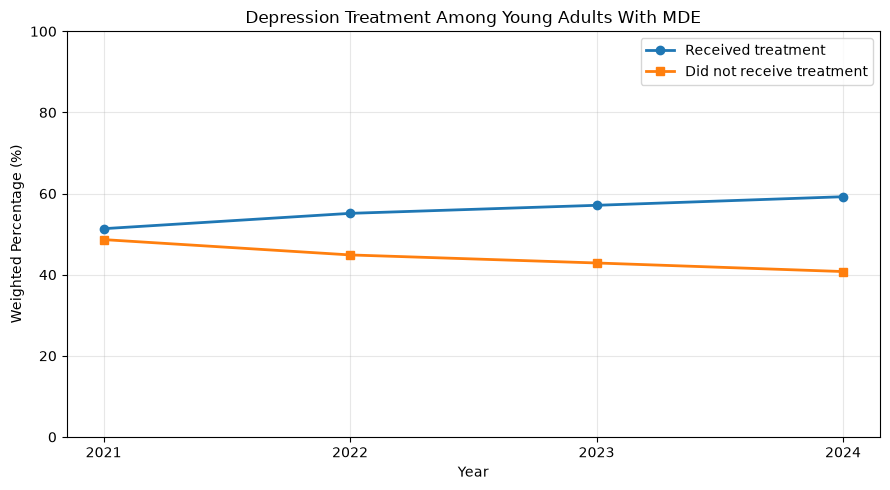

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    eda3_summary.index,
    eda3_summary["treatment_rate"],
    marker="o",
    linewidth=2,
    label="Received treatment"
)

ax.plot(
    eda3_summary.index,
    eda3_summary["untreated_rate"],
    marker="s",
    linewidth=2,
    label="Did not receive treatment"
)

ax.set_title("Depression Treatment Among Young Adults With MDE")
ax.set_xlabel("Year")
ax.set_ylabel("Weighted Percentage (%)")
ax.set_xticks([2021, 2022, 2023, 2024])
ax.set_ylim(0, 100)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

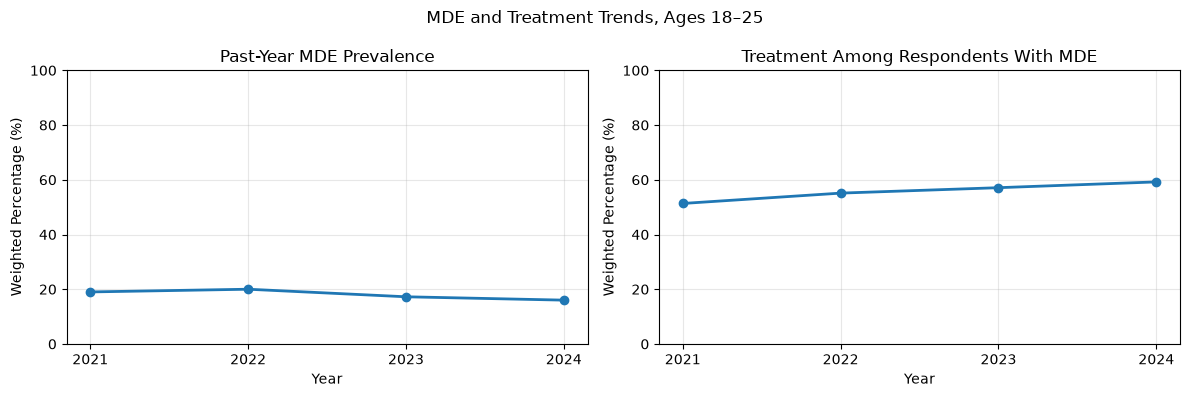

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    eda3_summary.index,
    eda3_summary["mde_prevalence"],
    marker="o",
    linewidth=2
)

axes[0].set_title("Past-Year MDE Prevalence")

axes[1].plot(
    eda3_summary.index,
    eda3_summary["treatment_rate"],
    marker="o",
    linewidth=2
)

axes[1].set_title("Treatment Among Respondents With MDE")

for ax in axes:
    ax.set_xlabel("Year")
    ax.set_ylabel("Weighted Percentage (%)")
    ax.set_xticks([2021, 2022, 2023, 2024])
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)

plt.suptitle("MDE and Treatment Trends, Ages 18–25")
plt.tight_layout()
plt.show()

## EDA 4: MDE Prevalence & Treatment Utilization by Sex 

- **MDE Prevalence by sex:** The weighted percentage of all female or male respondents aged 18-25 who have experienced MDE in the past year.
- **Treatment Utilization by sex:** The weighted percentage of female or male respondents with past-year MDE who reported depression-related treatment. 

**Treatment Differences By Sex:** Across the four years, female young adults experiencing MDE have consistently reported higher depression-related treatment rates than males. 59% of femals with MDE reported receiving treatment in 2021 compared with 35.63% of males, overall a 23.37% difference. 

**Changes in Treatment Utilization:** Treatment rates for both groups increased between 2021 and 2024. The increase was larger among males, as their treatment rate rose from 35.63% to 53.20% compared to females as their treatment rate increase from 59% to 63.08%. 

**Differences in MDE Prevalence:** Females aged 18-25 consistently experience higher MDE prevalence than males. Female MDE prevalence declined from 25.47% in 2021 to 19.61% in 2024, while male prevalence remained relatively stable, changing from 12.50% to 12.45%. 

**Relationship between Prevalence and Treatment:** Females experienced both higher MDE prevalence and higher treatment utilization throughout the study. Males experienced lower MDE prevalence but were less likely to report receiving treatment when experiencing MDE. 

In [17]:
sex_results = []
for (year, sex), group in mde_adults.groupby(["year", "sex"]):
    sex_results.append({
        "year": year,
        "sex": sex,
        "treatment_rate": weighted_pct(group, "mde_tx"),
        "sample_size": group["mde_tx"].isin([0, 1]).sum()
    })

sex_summary = pd.DataFrame(sex_results)
display(sex_summary.round(2))

,year,sex,treatment_rate,sample_size
0,2021,Female,59.000,1608
1,2021,Male,35.630,734
2,2022,Female,60.600,1678
3,2022,Male,45.840,888
4,2023,Female,61.820,1507
5,2023,Male,49.170,734
6,2024,Female,63.080,1442
7,2024,Male,53.200,767


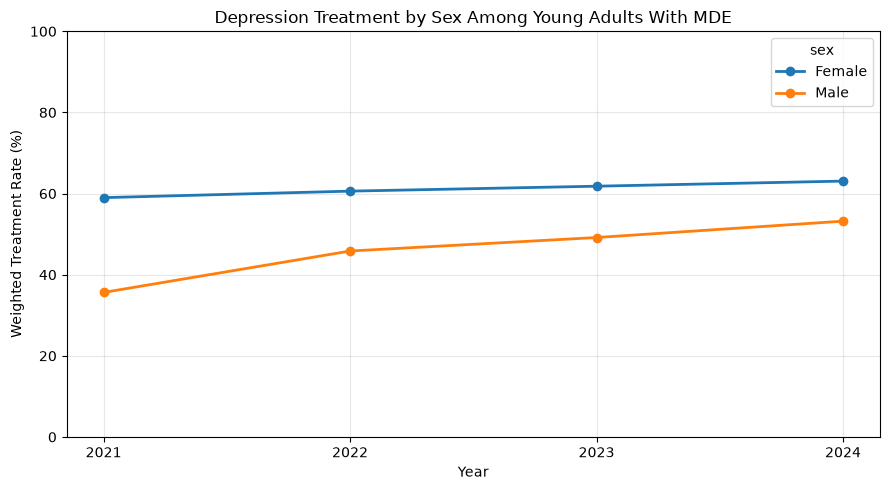

In [18]:
sex_plot = sex_summary.pivot(
    index="year",
    columns="sex",
    values="treatment_rate"
)

ax = sex_plot.plot(figsize=(9, 5), marker="o", linewidth=2)

ax.set_title("Depression Treatment by Sex Among Young Adults With MDE")
ax.set_xlabel("Year")
ax.set_ylabel("Weighted Treatment Rate (%)")
ax.set_xticks([2021, 2022, 2023, 2024])
ax.set_ylim(0, 100)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

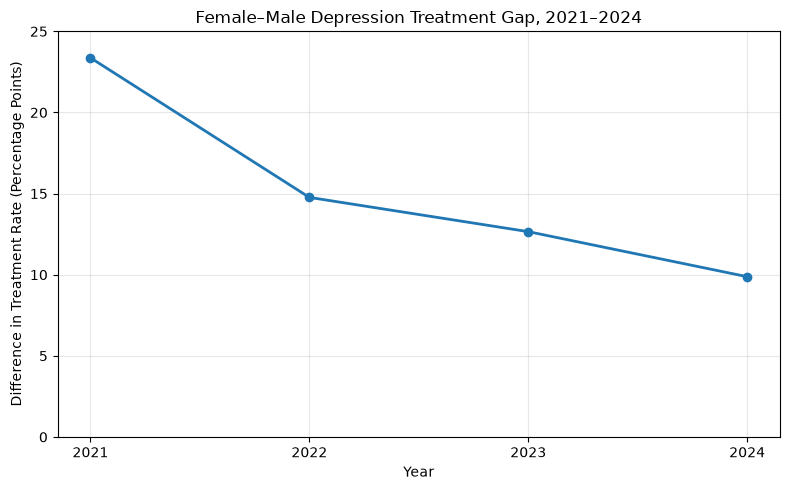

In [19]:
sex_gap = sex_plot["Female"] - sex_plot["Male"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    sex_gap.index,
    sex_gap.values,
    marker="o",
    linewidth=2
)

ax.set_title("Female–Male Depression Treatment Gap, 2021–2024")
ax.set_xlabel("Year")
ax.set_ylabel("Difference in Treatment Rate (Percentage Points)")
ax.set_xticks([2021, 2022, 2023, 2024])
ax.set_ylim(0, 25)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
sex_mde_results = []

for (year, sex), group in adults.groupby(["year", "sex"]):
    sex_mde_results.append({
        "year": year,
        "sex": sex,
        "mde_prevalence": weighted_pct(group, "mde_py")
    })

sex_mde_summary = pd.DataFrame(sex_mde_results)

display(sex_mde_summary.round(2))

,year,sex,mde_prevalence
0,2021,Female,25.470
1,2021,Male,12.500
2,2022,Female,25.400
3,2022,Male,14.700
4,2023,Female,21.810
5,2023,Male,12.740
6,2024,Female,19.610
7,2024,Male,12.450


In [21]:
sex_comparison = pd.merge(
    sex_mde_summary,
    sex_summary[["year", "sex", "treatment_rate"]],
    on=["year", "sex"]
)

display(sex_comparison.round(2))

,year,sex,mde_prevalence,treatment_rate
0,2021,Female,25.470,59.000
1,2021,Male,12.500,35.630
2,2022,Female,25.400,60.600
3,2022,Male,14.700,45.840
4,2023,Female,21.810,61.820
5,2023,Male,12.740,49.170
6,2024,Female,19.610,63.080
7,2024,Male,12.450,53.200


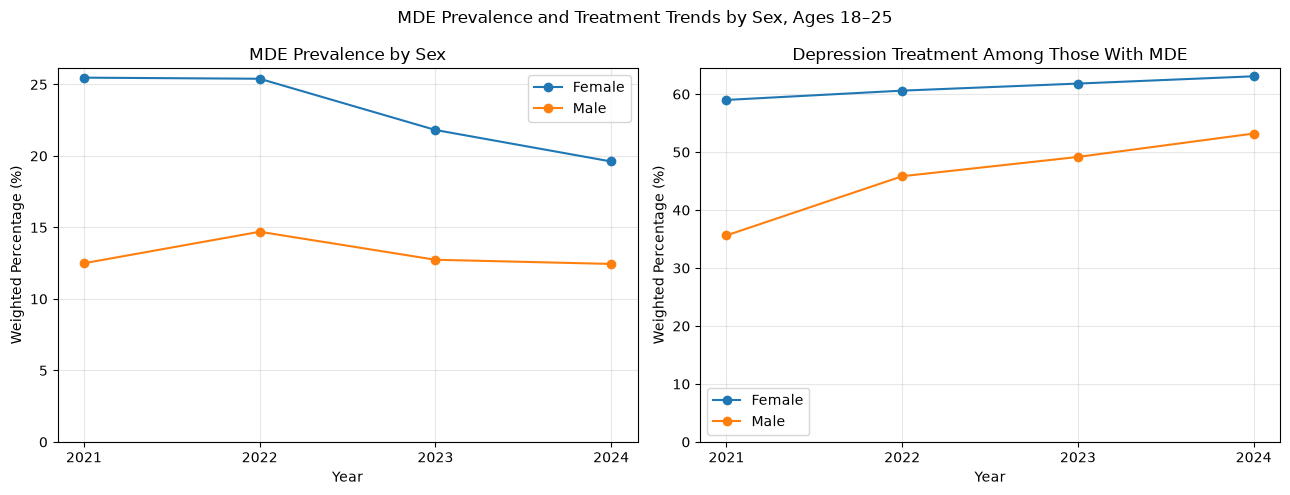

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for sex, group in sex_comparison.groupby("sex"):
    axes[0].plot(
        group["year"],
        group["mde_prevalence"],
        marker="o",
        label=sex
    )

    axes[1].plot(
        group["year"],
        group["treatment_rate"],
        marker="o",
        label=sex
    )

axes[0].set_title("MDE Prevalence by Sex")
axes[1].set_title("Depression Treatment Among Those With MDE")

for ax in axes:
    ax.set_xlabel("Year")
    ax.set_ylabel("Weighted Percentage (%)")
    ax.set_xticks([2021, 2022, 2023, 2024])
    ax.set_ylim(bottom=0)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("MDE Prevalence and Treatment Trends by Sex, Ages 18–25")
plt.tight_layout()
plt.show()